# 02 — Pre-trained encoders for the text layer

**Question:** do pre-trained language models (encoders) beat the TF-IDF baseline from notebook 01, especially on
**lists the model has never seen** — the weakness we found (ML-part recall 0.74 → 0.48)?

| Step | What | Status |
|---|---|---|
| 4a | Traditional ML (notebook 01) — best: char TF-IDF + LR without list name | done |
| **4b** | **Pre-trained encoders (this notebook)** | **now** |
| 4c | Prompted LLMs | next |

**What an encoder is.** A neural network pre-trained on billions of sentences to turn text into a vector
(a list of numbers, here 384–1024 of them) where texts with similar *meaning* get similar vectors — even with no
shared words and in different languages: *"Asesinato"* and *"murder"* land close together. TF-IDF cannot do this;
it only matches characters it has seen.

**Three ways to use an encoder, all tested here**

| Way | How | Cost | Strength |
|---|---|---|---|
| **Frozen embeddings + classifier** | encoder turns each record into a vector once; a logistic regression per label learns on the vectors | encode once (minutes on CPU), train in seconds | cheap, robust with 900 records |
| **Zero-shot by label definition** | encode the taxonomy *definition* of each label; score = similarity(record, definition) | no training at all | works for labels with almost no examples, and for new lists |
| **Fine-tuning** | all encoder weights are adjusted to our 18 labels | ~hours on this CPU | usually best when data is enough |

### Which encoders, and why (research summary)

Constraints (first run): **CPU-only laptop** (Intel i5-1335U, 16 GB, no GPU); the code uses a CUDA GPU automatically when present, **multilingual** text (English, German SECO,
Spanish/French/Portuguese Interpol charges), **long** records (up to ~5,800 characters), 900 labelled records, 18 labels.

| # | Model | Size | Why chosen |
|---|---|---|---|
| E0 | `sentence-transformers/all-MiniLM-L6-v2` | 22M, English only | control: tells us whether *multilingual* matters |
| E1 | `intfloat/multilingual-e5-small` | 118M, ~100 languages | the standard small multilingual baseline, fast on CPU |
| E2 | `intfloat/multilingual-e5-base` | 278M | same family, bigger: does size help? |
| E3 | `BAAI/bge-m3` | 568M, 8k-token context | strongest widely used open multilingual embedding model; handles long text |
| FT | `multilingual-e5-small`, **fine-tuned** | 118M | largest model that fine-tunes in reasonable time on this CPU |

Considered and not used now:
* **ModernBERT / DeBERTa-v3 (English)** — strong in English, weak multilingual coverage; our hardest errors are non-English.
* **mDeBERTa-v3 / XLM-R / mmBERT full fine-tuning** — good multilingual encoders (mmBERT reports gains over XLM-R),
  but 2–5× slower than e5-small to fine-tune on CPU; worth it later with a GPU if fine-tuning wins here.
* **SetFit** (few-shot contrastive fine-tuning) — strongest at 8–32 examples per class and single-label tasks;
  reported weaker on multi-label; we have more data than its sweet spot.
* **EmbeddingGemma-300m** — reported as the best open multilingual embedder under 500M params, but gated on
  Hugging Face (licence must be accepted on an account) — a candidate for a later run.

### How results are reported (the same views as notebook 01, now in `scripts/experimentKit.py`)

Every approach is run under **two protocols** and reported in **the same score card**:

* **Seen lists** — 5-fold multi-label stratified CV (identical folds to notebook 01).
* **Unseen lists** — 5 **list-grouped** folds: each list is entirely in one test fold, so it is never seen in training.
  (Harsher than notebook 01's leave-one-list-out, which trained on 28 of 29 lists; the baseline is re-run here under the
  same folds so the comparison is fair.)

| View | Question it answers |
|---|---|
| whole P / R / micro-F1 | what the customer sees: lookup ∪ model, all 23 labels, all label instances |
| whole macro-F1 (23) and (18, no rare) | same, every label equal; with and without the 5 rare labels |
| text-layer macro-F1 | the 15 labels the lookup handles badly |
| **ML part P / R / F1** | only label instances the lookup did not give — the model's own quality (**headline**) |
| ML part R incl. rare | the same recall when the 5 rare labels are counted as misses |
| part D | random part only (small, sanity check) |
| macro PR-AUC | ranking quality, independent of the threshold |

In [1]:
import json
import os
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import openpyxl
import pandas as pd
import torch
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
from sklearn.model_selection import GroupKFold
from iterstrat.ml_stratifiers import MultilabelStratifiedKFold

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 70, "display.width", 220, "display.precision", 3)
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3})

RESEARCH = Path.cwd().parent
sys.path.insert(0, str(RESEARCH / "scripts"))
from experimentKit import (SEED, Data, apply_tiers, best_threshold, crossfit_predict, full_predictions, label_tiers,
                           per_label, per_segment, score_views, tier_view)

CACHE = RESEARCH / "cache"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE)
CACHE.mkdir(exist_ok=True)
d = Data()
df, Y, L = d.df, d.Y, d.L
YM = Y[:, d.modelled]
PROTOCOLS = {"seen": d.seen_folds(), "unseen": d.unseen_folds()}
print(f"records={len(df)}  modelled labels={len(d.modelled)}  text-layer labels={len(d.text_layer)}  rare={[d.short[i] for i in d.rare]}")
for f in range(5):
    m = PROTOCOLS["unseen"] == f
    print(f"unseen fold {f}: {m.sum():3d} records | lists: {', '.join(sorted(df.loc[m, 'source'].unique()))}")

device: cuda
records=900  modelled labels=18  text-layer labels=15  rare=['RCA', 'Securities', 'Environmental', 'Jurisdiction Risk', 'State-Owned']
unseen fold 0:  82 records | lists: ATC-DESIGNATED-TERRORIST-INDIVIDUALS, FBI-WANTED
unseen fold 1: 134 records | lists: INTERPOL-RED-NOTICES, OFAC-SDN
unseen fold 2: 267 records | lists: ADB-DEBARMENT-SUSPENSION, ATC-DESIGNATED-TERRORIST-GROUPS, CFTC-RED-LIST, COMELEC-2025-SENATORS, DFAT, EU-DESIGNATED-VESSELS, GPPB-BLACKLISTED-ENTITIES, OFAC-NON-SDN, UKSL, UN-SANCTIONS, WORLD-BANK-OTHER-SANCTIONS
unseen fold 3: 267 records | lists: AFDB-DEBARRED-ENTITIES, CIA-WORLD-LEADERS-HISTORICAL, DILG-LOCAL-OFFICIALS, DMW-RECRUITMENT-AGENCIES, DNFBP, EU-FINANCIAL-SANCTIONS, NCA-MOST-WANTED, PH-HOUSE-MEMBERS, US-MARSHALS-PROFILED-FUGITIVES, US-STATE-TERRORIST-EXCLUSION, WORLD-BANK-DEBARRED
unseen fold 4: 150 records | lists: EU-MOST-WANTED, EU-TRAVEL-BAN, SECO-SANCTIONS


## 1. Shared machinery
* `head_scores` trains one logistic regression per label on any feature matrix, and **tunes the regularisation
  strength C** (how strongly the model is kept simple) inside each training fold: an inner 3-fold split picks the C
  with the best macro PR-AUC. Under the unseen protocol the inner split is also list-grouped, so C is chosen for
  generalisation to new lists. The test fold never influences C.
* Scores are probabilities, so different models can be averaged (ensembles, section 5).
* `RESULTS` collects every approach × protocol into one score card.

In [2]:
def fit_label_models(Xtr, Ytr, C):
    return [LogisticRegression(C=C, class_weight="balanced", solver="liblinear", max_iter=3000).fit(Xtr, Ytr[:, j])
            if 0 < Ytr[:, j].sum() < len(Ytr) else None for j in range(Ytr.shape[1])]

def predict_label_models(models, X, Ytr):
    return np.column_stack([m.predict_proba(X)[:, 1] if m is not None else np.full(X.shape[0], float(Ytr[:, j].mean()))
                            for j, m in enumerate(models)])

def inner_splits(idx, protocol):
    if protocol == "unseen":
        return GroupKFold(3).split(idx, groups=df["source"].values[idx])
    return MultilabelStratifiedKFold(3, shuffle=True, random_state=SEED).split(idx, YM[idx])

def head_scores(featurise, protocol, Cs=(0.25, 1, 4, 16)):
    """Out-of-fold probabilities for the 18 modelled labels with C tuned per outer fold; returns (S, chosen Cs)."""
    folds, S, chosen = PROTOCOLS[protocol], np.zeros(YM.shape), []
    for f in range(5):
        tr, te = np.flatnonzero(folds != f), np.flatnonzero(folds == f)
        Xtr, Xte = featurise(tr, te)
        best = (-1, Cs[0])
        for C in Cs:
            aps = []
            for itr, iva in inner_splits(tr, protocol):
                Si = predict_label_models(fit_label_models(Xtr[itr], YM[tr][itr], C), Xtr[iva], YM[tr][itr])
                aps += [average_precision_score(YM[tr][iva, j], Si[:, j]) for j in range(YM.shape[1]) if YM[tr][iva, j].sum()]
            best = max(best, (np.mean(aps), C))
        chosen.append(best[1])
        S[te] = predict_label_models(fit_label_models(Xtr, YM[tr], best[1]), Xte, YM[tr])
    return S, chosen

RESULTS, SCORES = [], {}

def record(name, protocol, S, P23=None, extra=None):
    """Add one approach × protocol to the score card (thresholds cross-fitted on the protocol's folds)."""
    if P23 is None:
        P23 = full_predictions(d, crossfit_predict(S, YM, PROTOCOLS[protocol]))
    SCORES[(name, protocol)] = (S, P23)
    RESULTS.append({"approach": name, "protocol": protocol, **score_views(d, P23, S), **(extra or {})})
    return P23

def card(cols=("whole micro-F1", "whole macro-F1 (23)", "whole macro-F1 (18, no rare)", "text-layer macro-F1",
               "ML part P", "ML part R", "ML part F1", "ML part R incl. rare", "part D text-layer macro-F1", "macro PR-AUC")):
    t = pd.DataFrame(RESULTS).set_index(["approach", "protocol"])
    return t[[c for c in cols if c in t.columns]]

## 2. Baseline under both protocols: char TF-IDF + LR, no list name (notebook 01's M8, C now tuned the same way)

In [3]:
def tfidf_features(tr, te):
    v = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True, max_features=120000)
    return v.fit_transform(df["text_noname"].values[tr]), v.transform(df["text_noname"].values[te])

for protocol in PROTOCOLS:
    t0 = time.time()
    S, Cs = head_scores(tfidf_features, protocol, Cs=(1, 4, 16))
    record("B0 char TF-IDF + LR", protocol, S, extra={"chosen C": str(Cs), "seconds": time.time() - t0})
card().loc[["B0 char TF-IDF + LR"]]

whole micro-F1  whole macro-F1 (23)  whole macro-F1 (18, no rare)  text-layer macro-F1  ML part P  ML part R  ML part F1  ML part R incl. rare  part D text-layer macro-F1  macro PR-AUC
approach            protocol                                                                                                                                                                                          
B0 char TF-IDF + LR seen               0.905                0.670                         0.856                0.830      0.806      0.721       0.761                 0.702                       0.827         0.899
                    unseen             0.763                0.533                         0.681                0.645      0.393      0.680       0.498                 0.662                       0.695         0.736

**Reading — baseline**

* Same model as notebook 01's M8 (char TF-IDF + LR, no list name), now with C tuned inside each training fold.
* **Seen lists:** ML-part F1 **0.761** (precision 0.806, recall 0.721).
* **Unseen lists:** ML-part F1 **0.498**. Recall holds up reasonably (0.721 → 0.680), but **precision collapses
  (0.806 → 0.393)**: on a list it has never seen, more than half of the labels the model adds are wrong.
* So the new-list problem is mainly a **precision** problem: the model fires on letter patterns that meant a label in
  the training lists' style but mean something else in a new list.
* This is the bar every encoder below must beat.

## 3. Frozen embeddings + logistic regression

**Long records:** encoders read at most 512 tokens (bge-m3: 8k). Each record (without the list-name line) is cut
into chunks of ≤180 words along its lines, every chunk is embedded, and the record vector is the **average** of its
chunk vectors. Nothing is lost from long wanted-list narratives.

**Prefixes:** e5 models expect `query: ` before symmetric inputs (classification); MiniLM and bge-m3 take none.

Embeddings are computed once and cached in `cache/` (git-ignored), so re-running the notebook takes minutes.

In [4]:
ENCODERS = {
    "E0 MiniLM-L6 (EN)": ("sentence-transformers/all-MiniLM-L6-v2", ""),
    "E1 mE5-small": ("intfloat/multilingual-e5-small", "query: "),
    "E2 mE5-base": ("intfloat/multilingual-e5-base", "query: "),
    "E3 bge-m3": ("BAAI/bge-m3", ""),
}

def chunks(text, max_words=180):
    """Pack a record's lines into chunks of at most max_words words (long lines are split)."""
    pieces = []
    for line in text.split("\n"):
        w = line.split()
        pieces += [" ".join(w[i:i + max_words]) for i in range(0, len(w), max_words)]
    out, cur = [], []
    for p in pieces:
        if cur and len(" ".join(cur).split()) + len(p.split()) > max_words:
            out.append("\n".join(cur)); cur = []
        cur.append(p)
    return out + (["\n".join(cur)] if cur else []) or [""]

_loaded = {}

def encoder(model_id):
    from sentence_transformers import SentenceTransformer
    if model_id not in _loaded:
        m = SentenceTransformer(model_id, device=DEVICE)
        m.max_seq_length = min(m.max_seq_length or 512, 512)
        _loaded[model_id] = m
    return _loaded[model_id]

def embed_texts(model_id, prefix, texts, batch_size=16):
    E = encoder(model_id).encode([prefix + t for t in texts], batch_size=batch_size, normalize_embeddings=True,
                                 show_progress_bar=False)
    return np.asarray(E)

def embed_records(name):
    """Record vectors (mean of chunk vectors), cached with the measured encoding time."""
    model_id, prefix = ENCODERS[name]
    slug = model_id.split("/")[-1]
    path, meta = CACHE / f"emb_{slug}.npy", CACHE / f"emb_{slug}.json"
    if path.exists():
        return np.load(path), json.load(open(meta))
    pieces, owner = [], []
    for i, t in enumerate(df["text_noname"]):
        for c in chunks(t):
            pieces.append(c); owner.append(i)
    t0 = time.time()
    E = embed_texts(model_id, prefix, pieces)
    secs = time.time() - t0
    X = np.zeros((len(df), E.shape[1]))
    np.add.at(X, owner, E)
    X /= np.linalg.norm(X, axis=1, keepdims=True)
    info = {"model": model_id, "dims": int(E.shape[1]), "chunks": len(pieces), "encode_seconds": round(secs, 1),
            "seconds_per_1000_records": round(1000 * secs / len(df), 1)}
    np.save(path, X); json.dump(info, open(meta, "w"))
    return X, info

EMB, EMB_INFO = {}, {}
for name in ENCODERS:
    EMB[name], EMB_INFO[name] = embed_records(name)
    print(name, EMB_INFO[name])

E0 MiniLM-L6 (EN) {'model': 'sentence-transformers/all-MiniLM-L6-v2', 'dims': 384, 'chunks': 1190, 'encode_seconds': 118.3, 'seconds_per_1000_records': 131.4}
E1 mE5-small {'model': 'intfloat/multilingual-e5-small', 'dims': 384, 'chunks': 1190, 'encode_seconds': 43.9, 'seconds_per_1000_records': 48.7}
E2 mE5-base {'model': 'intfloat/multilingual-e5-base', 'dims': 768, 'chunks': 1190, 'encode_seconds': 322.1, 'seconds_per_1000_records': 357.8}
E3 bge-m3 {'model': 'BAAI/bge-m3', 'dims': 1024, 'chunks': 1190, 'encode_seconds': 3414.6, 'seconds_per_1000_records': 3794.1}


In [5]:
for name in ENCODERS:
    X = EMB[name]
    for protocol in PROTOCOLS:
        t0 = time.time()
        S, Cs = head_scores(lambda tr, te: (X[tr], X[te]), protocol)
        record(name + " + LR", protocol, S, extra={"chosen C": str(Cs), "seconds": time.time() - t0})
card().sort_index(level=1)

,,whole micro-F1,whole macro-F1 (23),"whole macro-F1 (18, no rare)",text-layer macro-F1,ML part P,ML part R,ML part F1,ML part R incl. rare,part D text-layer macro-F1,macro PR-AUC
approach,protocol,,,,,,,,,,
B0 char TF-IDF + LR,seen,0.905,0.670,0.856,0.830,0.806,0.721,0.761,0.702,0.827,0.899
E0 MiniLM-L6 (EN) + LR,seen,0.871,0.621,0.793,0.758,0.683,0.674,0.678,0.656,0.835,0.841
E1 mE5-small + LR,seen,0.874,0.629,0.804,0.769,0.702,0.669,0.685,0.651,0.844,0.847
E2 mE5-base + LR,seen,0.871,0.621,0.793,0.758,0.678,0.686,0.682,0.668,0.757,0.844
E3 bge-m3 + LR,seen,0.887,0.639,0.817,0.785,0.730,0.712,0.721,0.693,0.883,0.864
B0 char TF-IDF + LR,unseen,0.763,0.533,0.681,0.645,0.393,0.680,0.498,0.662,0.695,0.736
E0 MiniLM-L6 (EN) + LR,unseen,0.755,0.491,0.627,0.579,0.380,0.564,0.454,0.549,0.610,0.595
E1 mE5-small + LR,unseen,0.742,0.508,0.650,0.599,0.358,0.643,0.460,0.626,0.675,0.607
E2 mE5-base + LR,unseen,0.754,0.505,0.645,0.593,0.378,0.646,0.477,0.629,0.603,0.617


**Reading — frozen encoders**

* **No frozen encoder beats TF-IDF, in any view.** Best ML-part F1: seen bge-m3 0.721 vs TF-IDF 0.761;
  unseen e5-base and bge-m3 0.477 vs TF-IDF 0.498. Ranking quality agrees (unseen macro PR-AUC 0.595–0.659 vs 0.736).
* **Multilingual helps a little on new lists:** unseen ML-part recall English MiniLM 0.564 vs multilingual 0.634–0.646.
* **Bigger is not clearly better:** e5-base (278M) and bge-m3 (568M) tie on unseen lists (0.477); e5-small (118M) 0.460.
* **Why encoders lose here:** each record becomes *one* averaged vector, so the single decisive phrase
  ("TAX EVASION" in a long Interpol record) is blurred by everything else; and 900 records are few for a classifier
  on 384–1,024 dense numbers. TF-IDF keeps every phrase as its own feature.
* **Cost** (CPU, old laptop): e5-small 49 s per 1,000 records, bge-m3 3,794 s — bge-m3 is not worth its cost.

## 4. Zero-shot: similarity to the label definitions
Each label's text = its **English definition, coverage and boundary** plus the **sample indicators** from the
taxonomy (`VV_Risk_Labels_Final_reviewed.xlsx`). Score = cosine similarity between a record and that text.
**No classifier is trained**; only one cut-off per label is chosen (cross-fitted). This is the only approach that
can score the 5 rare labels and does not depend on which lists were in training.

Two uses: (a) zero-shot on its own, (b) **hybrid** — the 23 similarities are added as extra features next to the
embedding (the definitions give the classifier prior knowledge of each label).

In [6]:
wb = openpyxl.load_workbook(RESEARCH / "data" / "taxonomy" / "VV_Risk_Labels_Final_reviewed.xlsx", read_only=True)
tax = {r[0]: r for r in wb["Risk Labels"].iter_rows(min_row=2, values_only=True) if r[0]}
def label_text(name):
    row = tax[name]
    indicators = "; ".join(l.split(" / ")[0].strip() for l in (row[4] or "").split("\n") if l.strip())
    return f"{name}. {row[2]}\nIndicators: {indicators}"
LABEL_TEXTS = [label_text(n) for n in d.labels]
print(LABEL_TEXTS[d.labels.index("Crime-Tax Crime")][:400], "…")

ZS = {}
for name in ENCODERS:
    model_id, prefix = ENCODERS[name]
    path = CACHE / f"labels_{model_id.split('/')[-1]}.npy"
    if not path.exists():
        np.save(path, embed_texts(model_id, prefix, LABEL_TEXTS))
    ZS[name] = EMB[name] @ np.load(path).T

zs_rows = []
for name in ENCODERS:
    Z = ZS[name]
    zs_rows.append({"encoder": name,
                    "macro PR-AUC, 18 modelled": np.mean([average_precision_score(Y[:, i], Z[:, i]) for i in d.modelled]),
                    "macro PR-AUC, 5 rare (with ≥1 positive)": np.mean([average_precision_score(Y[:, i], Z[:, i]) for i in d.rare if Y[:, i].sum()])})
zs_tab = pd.DataFrame(zs_rows).set_index("encoder")
ZS_BEST = zs_tab["macro PR-AUC, 18 modelled"].idxmax()
zs_tab.round(3)

Crime-Tax Crime. Definition: Reporting of deliberate tax evasion, fraud or concealment constituting a criminal breach of tax obligations, or an explicit tax-crime allegation.
Coverage: Tax evasion, deliberately false returns, concealed taxable income, fraudulent tax claims/refunds, fabricated documents for unlawful tax reduction and other specifically reported tax offenses. Preserve tax type, auth …


,"macro PR-AUC, 18 modelled","macro PR-AUC, 5 rare (with ≥1 positive)"
encoder,,
E0 MiniLM-L6 (EN),0.475,0.122
E1 mE5-small,0.343,0.113
E2 mE5-base,0.297,0.174
E3 bge-m3,0.430,0.120


In [7]:
Z = ZS[ZS_BEST]
for protocol in PROTOCOLS:
    P_all = crossfit_predict(Z, Y, PROTOCOLS[protocol])
    record(f"Z zero-shot ({ZS_BEST.split()[0]})", protocol, Z[:, d.modelled], P23=P_all)
    Xh = np.hstack([EMB[ZS_BEST], Z])
    S, Cs = head_scores(lambda tr, te: (Xh[tr], Xh[te]), protocol)
    record(f"H {ZS_BEST} + definitions + LR", protocol, S, extra={"chosen C": str(Cs)})

rare_rows = []
for i in d.rare:
    if Y[:, i].sum() == 0:
        continue
    order = np.argsort(-Z[:, i])
    rank = [int(np.flatnonzero(order == k)[0]) + 1 for k in np.flatnonzero(Y[:, i])]
    rare_rows.append({"rare label": d.short[i], "positives": int(Y[:, i].sum()), "ranks of the positives among 900": sorted(rank),
                      "found in top 25": sum(r <= 25 for r in rank), "found in top 50": sum(r <= 50 for r in rank)})
print(f"Rare labels — where zero-shot ({ZS_BEST}) ranks the true positives (1 = most similar of 900 records):")
pd.DataFrame(rare_rows).set_index("rare label")

Rare labels — where zero-shot (E0 MiniLM-L6 (EN)) ranks the true positives (1 = most similar of 900 records):


,positives,ranks of the positives among 900,found in top 25,found in top 50
rare label,,,,
RCA,1,[481],0,0
Securities,5,"[5, 15, 18, 36, 44]",3,5
Environmental,7,"[1, 2, 31, 49, 256, 529, 663]",2,4
State-Owned,4,"[53, 62, 94, 454]",0,0


**Reading — zero-shot**

* **On its own it is weak:** ML-part F1 0.303 (seen) / 0.261 (unseen); precision only 0.17–0.21. Similarity to a
  definition cannot tell "Tax Crime" from "tax identification number".
* Surprisingly the **English MiniLM** ranks best (macro PR-AUC 0.475 vs 0.297–0.430 for the multilingual models).
* **Hybrid** (the 23 similarities added as features) does **not** help: unseen 0.431 vs 0.454 for MiniLM alone.
* **Useful as a shortlist for rare labels:** Securities — all 5 positives in the top 50 of 900 (ranks 5, 15, 18, 36, 44);
  Environmental — 4 of 7 in the top 50, two at ranks 1 and 2. **Not** State-Owned (best rank 53) or RCA (rank 481).
  So: a reviewer shortlist for Securities and Environmental, nothing more.

## 5. Ensembles: TF-IDF + embeddings
The two feature types make different mistakes (characters vs meaning). Averaging their probabilities is the
cheapest way to combine them.

In [8]:
best_frozen = card().xs("unseen", level="protocol").loc[[n + " + LR" for n in ENCODERS], "ML part F1"].idxmax()
hybrid = f"H {ZS_BEST} + definitions + LR"
for other in sorted({best_frozen, hybrid}):
    for protocol in PROTOCOLS:
        S = (SCORES[("B0 char TF-IDF + LR", protocol)][0] + SCORES[(other, protocol)][0]) / 2
        record(f"ENS B0 + {other.split(' + ')[0]}" + (" (+defs)" if other == hybrid else ""), protocol, S)
print("best frozen encoder on unseen lists:", best_frozen)
card().sort_index(level=1).loc[lambda t: t.index.get_level_values(0).str.startswith(("ENS", "B0"))]

best frozen encoder on unseen lists: E2 mE5-base + LR


,,whole micro-F1,whole macro-F1 (23),"whole macro-F1 (18, no rare)",text-layer macro-F1,ML part P,ML part R,ML part F1,ML part R incl. rare,part D text-layer macro-F1,macro PR-AUC
approach,protocol,,,,,,,,,,
B0 char TF-IDF + LR,seen,0.905,0.670,0.856,0.830,0.806,0.721,0.761,0.702,0.827,0.899
ENS B0 + E2 mE5-base,seen,0.901,0.662,0.846,0.821,0.776,0.736,0.756,0.716,0.814,0.904
ENS B0 + H E0 MiniLM-L6 (EN) (+defs),seen,0.904,0.661,0.845,0.817,0.793,0.732,0.762,0.713,0.831,0.897
B0 char TF-IDF + LR,unseen,0.763,0.533,0.681,0.645,0.393,0.680,0.498,0.662,0.695,0.736
ENS B0 + E2 mE5-base,unseen,0.795,0.562,0.719,0.680,0.455,0.697,0.551,0.679,0.750,0.728
ENS B0 + H E0 MiniLM-L6 (EN) (+defs),unseen,0.760,0.516,0.659,0.615,0.388,0.658,0.488,0.640,0.662,0.710


**Reading — ensembles**

* **TF-IDF + e5-base (average of the two probabilities) is the best so far on unseen lists:** ML-part F1
  0.498 → **0.551**; precision 0.393 → 0.455, recall 0.680 → 0.697; whole micro-F1 0.763 → 0.795.
* On seen lists it is equal to TF-IDF (0.756 vs 0.761) — the gain is specifically on new lists.
* Why it helps: the two models make different mistakes (letters vs meaning); averaging dampens the over-confident,
  list-style-driven scores of either one.
* Ranking quality does not improve (unseen PR-AUC 0.728 vs 0.736), so the gain is at the chosen thresholds,
  not a better ordering overall.
* The ensemble with the hybrid MiniLM model adds nothing (0.488).

## 6. Fine-tuning `multilingual-e5-small`

All 118M weights are trained on our labels: encoder → mean of token vectors → one output per label →
binary cross-entropy loss (each label is its own yes/no). Rare-positive labels get a higher loss weight
(`pos_weight` = negatives / positives, capped at 10), the neural-network version of `class_weight="balanced"`.

**Hyper-parameter tuning:** on the training part of seen fold 0, an inner 80/20 split compares two learning rates
(3e-5, 8e-5) for up to 6 epochs; the (learning rate, epochs) pair with the best inner macro PR-AUC is then used for
every fold of both protocols. Records are truncated to 320 tokens (median record ≈ 150 tokens).
Each trained fold's test scores are cached, so an interrupted run resumes where it stopped.

In [9]:
from torch import nn
from transformers import AutoModel, AutoTokenizer, get_linear_schedule_with_warmup

torch.set_num_threads(os.cpu_count())
FT_ID, FT_PREFIX, MAX_LEN, BATCH = "intfloat/multilingual-e5-small", "query: ", 320, 16
tok = AutoTokenizer.from_pretrained(FT_ID)
ENC = tok([FT_PREFIX + t for t in df["text_noname"]], truncation=True, max_length=MAX_LEN, padding=False)
print("records truncated at 320 tokens:", sum(len(x) >= MAX_LEN for x in ENC["input_ids"]))

class Tagger(nn.Module):
    def __init__(self, n):
        super().__init__()
        self.enc = AutoModel.from_pretrained(FT_ID)
        self.head = nn.Linear(self.enc.config.hidden_size, n)
    def forward(self, ids, mask):
        h = self.enc(input_ids=ids, attention_mask=mask).last_hidden_state
        return self.head((h * mask[..., None]).sum(1) / mask.sum(1, keepdim=True))

def batches(idx, shuffle, rng=None):
    """Mini-batches of similar-length records (less padding = faster on CPU)."""
    idx = rng.permutation(idx) if shuffle else np.asarray(idx)
    size = lambda i: len(ENC["input_ids"][i])
    idx = np.concatenate([sorted(idx[k:k + BATCH * 8], key=size) for k in range(0, len(idx), BATCH * 8)]) if len(idx) else idx
    for k in range(0, len(idx), BATCH):
        b = idx[k:k + BATCH]
        p = tok.pad({"input_ids": [ENC["input_ids"][i] for i in b], "attention_mask": [ENC["attention_mask"][i] for i in b]},
                    return_tensors="pt")
        yield b, p["input_ids"].to(DEVICE), p["attention_mask"].to(DEVICE)

def predict(model, idx):
    model.eval(); out = np.zeros((len(idx), YM.shape[1])); pos = {i: k for k, i in enumerate(idx)}
    with torch.no_grad():
        for b, ids, mask in batches(idx, False):
            out[[pos[i] for i in b]] = torch.sigmoid(model(ids, mask)).cpu().numpy()
    return out

def train(tr, lr, epochs, eval_idx=None):
    """Fine-tune on tr; returns the model and (if eval_idx) macro PR-AUC after every epoch."""
    torch.manual_seed(SEED); rng = np.random.default_rng(SEED)
    model = Tagger(YM.shape[1]).to(DEVICE)
    pos = YM[tr].sum(0)
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(np.clip((len(tr) - pos) / np.maximum(pos, 1), 1, 10), dtype=torch.float, device=DEVICE))
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    steps = epochs * int(np.ceil(len(tr) / BATCH))
    sched = get_linear_schedule_with_warmup(opt, int(0.1 * steps), steps)
    curve = []
    for ep in range(epochs):
        model.train(); t0 = time.time()
        for b, ids, mask in batches(tr, True, rng):
            loss = loss_fn(model(ids, mask), torch.tensor(YM[b], dtype=torch.float, device=DEVICE))
            loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step(); sched.step(); opt.zero_grad()
        if eval_idx is not None:
            Sv = predict(model, eval_idx)
            curve.append(np.mean([average_precision_score(YM[eval_idx, j], Sv[:, j]) for j in range(YM.shape[1]) if YM[eval_idx, j].sum()]))
        print(f"  lr={lr:g} epoch {ep + 1}/{epochs} {time.time() - t0:.0f}s" + (f" inner PR-AUC={curve[-1]:.3f}" if curve else ""), flush=True)
    return model, curve

tune_path = CACHE / "ft_tuning.json"
if tune_path.exists():
    TUNE = json.load(open(tune_path))
else:
    tr0 = np.flatnonzero(PROTOCOLS["seen"] != 0)
    a, b = next(MultilabelStratifiedKFold(5, shuffle=True, random_state=SEED).split(tr0, YM[tr0]))
    TUNE = {"curves": {}}
    for lr in (3e-5, 8e-5):
        _, curve = train(tr0[a], lr, 6, eval_idx=tr0[b])
        TUNE["curves"][str(lr)] = curve
    lr_best, curve = max(TUNE["curves"].items(), key=lambda kv: max(kv[1]))
    TUNE.update(lr=float(lr_best), epochs=int(np.argmax(curve)) + 1)
    json.dump(TUNE, open(tune_path, "w"))
print("chosen:", {k: v for k, v in TUNE.items() if k != "curves"})
pd.DataFrame(TUNE["curves"], index=range(1, 7)).rename_axis("epoch").round(3)

records truncated at 320 tokens: 128
chosen: {'lr': 8e-05, 'epochs': 6}


,3e-05,8e-05
epoch,,
1,0.371,0.524
2,0.550,0.606
3,0.655,0.716
4,0.686,0.811
5,0.685,0.809
6,0.691,0.827


In [10]:
FT_SECONDS = {}
for protocol in PROTOCOLS:
    folds, S = PROTOCOLS[protocol], np.zeros(YM.shape)
    t_all = time.time()
    for f in range(5):
        path = CACHE / f"ft_{protocol}_fold{f}.npy"
        te = np.flatnonzero(folds == f)
        if not path.exists():
            print(f"{protocol} fold {f}", flush=True)
            model, _ = train(np.flatnonzero(folds != f), TUNE["lr"], TUNE["epochs"])
            np.save(path, predict(model, te))
        S[te] = np.load(path)
    FT_SECONDS[protocol] = time.time() - t_all
    record("FT mE5-small fine-tuned", protocol, S)
card().sort_index(level=1).loc[lambda t: t.index.get_level_values(0).str.startswith(("FT", "B0"))]

,,whole micro-F1,whole macro-F1 (23),"whole macro-F1 (18, no rare)",text-layer macro-F1,ML part P,ML part R,ML part F1,ML part R incl. rare,part D text-layer macro-F1,macro PR-AUC
approach,protocol,,,,,,,,,,
B0 char TF-IDF + LR,seen,0.905,0.670,0.856,0.830,0.806,0.721,0.761,0.702,0.827,0.899
FT mE5-small fine-tuned,seen,0.865,0.595,0.761,0.718,0.656,0.680,0.668,0.662,0.729,0.809
B0 char TF-IDF + LR,unseen,0.763,0.533,0.681,0.645,0.393,0.680,0.498,0.662,0.695,0.736
FT mE5-small fine-tuned,unseen,0.710,0.469,0.600,0.552,0.309,0.618,0.412,0.602,0.636,0.563


In [11]:
for protocol in PROTOCOLS:
    S = (SCORES[("B0 char TF-IDF + LR", protocol)][0] + SCORES[("FT mE5-small fine-tuned", protocol)][0]) / 2
    record("ENS B0 + FT", protocol, S)

**Reading — fine-tuning**

* Run on the **RTX 4070**: ~6 s per epoch; all 10 folds (both protocols) in 424 s, vs ~23 min **per fold** on the old CPU.
  Seen-list result 0.668 matches the earlier CPU run (0.669) — the result is reproducible.
* **Fine-tuning loses to TF-IDF:** seen 0.668 vs 0.761; unseen **0.412** vs 0.498 — the weakest trained approach on
  unseen lists, with precision 0.309.
* **Ensemble TF-IDF + fine-tuned:** best of all on seen lists (0.774) but only 0.504 on unseen lists (≈ baseline).
  What it learns is mostly the training lists' patterns again.
* Limits of this run (all now cheap to test on the GPU): input cut at 320 tokens (128 records truncated); the tuning
  curve was still rising at epoch 6 (inner PR-AUC 0.809 → 0.827); one seed; two learning rates.

## 7. The full score card
Sorted by the headline: **ML-part F1 on unseen lists**. Green = better within the column.

In [12]:
full = card()
order = full.xs("unseen", level="protocol")["ML part F1"].sort_values(ascending=False).index
full = full.reindex(pd.MultiIndex.from_product([order, ["seen", "unseen"]])).dropna(how="all")
full.to_csv(RESEARCH / "results" / "encoders_score_card.csv")
np.savez(CACHE / "nb02_predictions.npz", **{f"{n} | {p}": P for (n, p), (_, P) in SCORES.items()})
full.style.format("{:.3f}").background_gradient(cmap="Greens", axis=0)

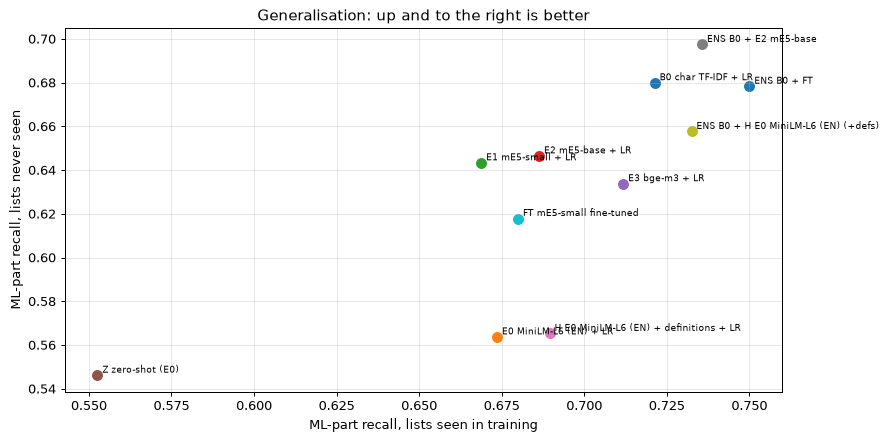

In [13]:
u = card().xs("unseen", level="protocol"); s = card().xs("seen", level="protocol")
fig, ax = plt.subplots(figsize=(10, 5))
for name in u.index:
    ax.scatter(s.loc[name, "ML part R"], u.loc[name, "ML part R"], s=60)
    ax.annotate(name, (s.loc[name, "ML part R"], u.loc[name, "ML part R"]), fontsize=7, xytext=(4, 2), textcoords="offset points")
ax.set_xlabel("ML-part recall, lists seen in training"); ax.set_ylabel("ML-part recall, lists never seen")
ax.set_title("Generalisation: up and to the right is better"); plt.tight_layout(); plt.show()

**Reading — score card**

* Order on the headline (unseen ML-part F1): **ENS TF-IDF + e5-base 0.551** > ENS TF-IDF + FT 0.504 > TF-IDF 0.498 >
  frozen encoders 0.454–0.477 > hybrid 0.431 > fine-tuned 0.412 > zero-shot 0.261.
* **Every trained** approach loses 0.20–0.27 F1 from seen to unseen lists, and in every case precision falls far more than recall.
* Whole-set micro-F1 (what a customer sees, lookup included): 0.905 seen vs at best 0.795 unseen.
* No whole-record model is near bank-grade on a new list.

## 8. Best approach vs baseline, label by label (unseen lists)

In [14]:
BEST = u["ML part F1"].drop(index=[i for i in u.index if i.startswith("Z ")]).idxmax()
print("best approach on unseen lists:", BEST)
pl_b = per_label(d, SCORES[("B0 char TF-IDF + LR", "unseen")][1])
pl_x = per_label(d, SCORES[(BEST, "unseen")][1], SCORES[(BEST, "unseen")][0])
pl_s = per_label(d, SCORES[(BEST, "seen")][1])
cmp = pd.DataFrame({"support": pl_x["support"], "lookup share": pl_x["lookup share"],
                    "baseline F1 (unseen)": pl_b["F1"], "best F1 (unseen)": pl_x["F1"], "best F1 (seen)": pl_s["F1"],
                    "baseline ML R (unseen)": pl_b["ML part R"], "best ML R (unseen)": pl_x["ML part R"],
                    "best P (unseen)": pl_x["P"], "best P 95% CI": pl_x["P 95% CI"], "best R 95% CI": pl_x["R 95% CI"]})
cmp = cmp[cmp["support"] > 0].sort_values("support", ascending=False)
cmp.to_csv(RESEARCH / "results" / "encoders_best_per_label.csv")
cmp.style.format({c: "{:.2f}" for c in cmp.columns if c not in ("support", "best P 95% CI", "best R 95% CI")}) \
    .background_gradient(cmap="RdYlGn", vmin=0.3, vmax=1, subset=["baseline ML R (unseen)", "best ML R (unseen)"])

best approach on unseen lists: ENS B0 + E2 mE5-base


,support,lookup share,baseline F1 (unseen),best F1 (unseen),best F1 (seen),baseline ML R (unseen),best ML R (unseen),best P (unseen),best P 95% CI,best R 95% CI
label,,,,,,,,,,
Sanctions,464,1.00,0.88,0.92,1.00,0.00,0.00,0.86,0.83–0.89,0.99–1.00
Law Enforcement,204,0.92,0.88,0.92,0.94,0.94,0.76,0.87,0.82–0.91,0.95–0.99
PEP,135,0.50,0.62,0.64,0.82,0.94,0.91,0.48,0.42–0.54,0.91–0.98
Violent Crime,102,0.07,0.70,0.70,0.85,0.67,0.77,0.63,0.54–0.71,0.69–0.85
Regulatory,99,1.00,0.82,0.89,0.97,nan,nan,0.80,0.73–0.87,0.96–1.00
Judicial,89,0.00,0.72,0.73,0.88,0.75,0.75,0.71,0.61–0.79,0.65–0.83
Terrorism,80,0.85,0.81,0.95,0.96,0.58,0.50,0.97,0.91–0.99,0.85–0.97
Fraud,56,0.04,0.79,0.83,0.88,0.69,0.80,0.87,0.75–0.93,0.68–0.89
Money Laundering,53,0.00,0.69,0.71,0.84,0.66,0.62,0.82,0.68–0.91,0.49–0.74


**Reading — per label (best = ENS TF-IDF + e5-base, unseen lists)**

* **Clear gains over TF-IDF:** Tax Crime F1 0.129 → 0.452 (ML-part recall 0.118 → 0.412), Terrorism 0.806 → 0.949,
  Trafficking 0.702 → 0.814, Fraud 0.788 → 0.833, Forgery 0.480 → 0.560, Cybercrime 0.784 → 0.854.
* **Losses:** Proliferation 0.852 → 0.698, Theft 0.468 → 0.383, Organized Crime 0.667 → 0.630, Corruption 0.627 → 0.593.
* **Weakest on new lists:** Theft 0.383, Tax 0.452, Forgery 0.560 — labels the lookup never gives and whose
  trigger words are ambiguous.
* **The model hurts labels the lookup already solves:** Sanctions comes 99.8% from the lookup, yet its whole-set F1 on
  unseen lists is 0.923 with precision 0.859 — the model *adds* wrong Sanctions labels on new lists. Same pattern for
  Regulatory (P 0.805) and Law Enforcement (P 0.870). This supports the "lookup only" tier for these three labels.
* PEP precision is only 0.480 (candidates and officials confused with PEPs).
* Intervals are wide for small labels (Tax recall 0.22–0.64), so per-label differences under ~0.1 are not reliable.

## 8b. Label tiers
With n true positives, even a perfect model only proves recall ≥ n / (n + 3.84) at 95% confidence
(15 → 0.80, 30 → 0.89, 50 → 0.93). So the model is made **responsible** only where there is enough evidence:

| Tier | Rule (from the data) | Model output |
|---|---|---|
| lookup only | the lookup gives ≥ 90% of the label's positives | dropped — the lookup decides |
| A validated ML | ≥ 50 positives the lookup misses | used |
| B provisional ML | 30–49 | used as a suggestion (review / LLM) |
| C no ML | < 30 | dropped — rules / LLM / review; promoted when it reaches 50 |

No label leaves the product; only the model's responsibility changes. "With tiers" = model output kept for A and B only.

In [15]:
for tier, labels in pd.Series(d.short).groupby(label_tiers(d)):
    print(f"{tier}: {', '.join(labels)}")
print("\nunseen lists, per tier:")
pd.concat({name: tier_view(d, SCORES[(name, "unseen")][1]).drop(columns="labels")
           for name in ("B0 char TF-IDF + LR", BEST)}, axis=1).round(3)

A validated ML: PEP, Fraud, Money Laundering, Violent Crime, Theft, Judicial
B provisional ML: Trafficking, Forgery, Organized Crime
C no ML: RCA, Corruption, Cybercrime, Tax Crime, Securities, Environmental, Terrorism, Proliferation, Human Rights, Jurisdiction Risk, State-Owned
lookup only: Sanctions, Regulatory, Law Enforcement

unseen lists, per tier:


B0 char TF-IDF + LR                                                               ENS B0 + E2 mE5-base                                                           
                 positives lookup misses model added added but wrong ML part P ML part R ML part F1 positives lookup misses model added added but wrong ML part P ML part R ML part F1
tier                                                                                                                                                                                  
lookup only                           18         236             220     0.068     0.889      0.126                      18         143             130     0.091     0.722      0.161
A validated ML                       411         564             272     0.518     0.710      0.599                     411         573             273     0.524     0.730      0.610
B provisional ML                     107         147              75     0.490     0.673      0.567                     107         125              53     0.576     0.673      0.621
C no ML                              109         140              93     0.336     0.431      0.378                     109         122              69     0.434     0.486      0.459

In [16]:
tier_cols = ["whole P", "whole R", "whole micro-F1", "ML part P", "ML part R", "ML part F1"]
tiered = pd.DataFrame({(name, protocol, view): score_views(d, P if view == "as is" else apply_tiers(d, P))
                       for name in ("B0 char TF-IDF + LR", BEST) for protocol in PROTOCOLS
                       for P in [SCORES[(name, protocol)][1]] for view in ("as is", "with tiers")}).T[tier_cols]
tiered.to_csv(RESEARCH / "results" / "encoders_tiers.csv")
tiered.round(3)

whole P  whole R  whole micro-F1  ML part P  ML part R  ML part F1
B0 char TF-IDF + LR  seen   as is         0.929    0.882           0.905      0.806      0.721       0.761
                            with tiers    0.946    0.835           0.887      0.830      0.599       0.696
                     unseen as is         0.681    0.866           0.763      0.393      0.680       0.498
                            with tiers    0.795    0.828           0.811      0.512      0.580       0.544
ENS B0 + E2 mE5-base seen   as is         0.916    0.888           0.901      0.776      0.736       0.756
                            with tiers    0.942    0.842           0.889      0.820      0.618       0.705
                     unseen as is         0.730    0.873           0.795      0.455      0.697       0.551
                            with tiers    0.806    0.832           0.819      0.533      0.592       0.561

**Reading — label tiers (unseen lists)**

* **Lookup-only labels: the model's additions are almost all wrong.** TF-IDF added 236 Sanctions / Regulatory /
  Law Enforcement labels the lookup did not give; **220 were wrong** (precision 0.068). Best ensemble: 130 of 143 wrong.
  These are a third of all wrong additions (TF-IDF: 220 of 660). Dropping the model for these three labels is a clear win.
* **Tier A** (6 labels, 411 positives the lookup misses): ML-part F1 0.599 (TF-IDF) / 0.610 (best).
  **Tier B** (3 labels, 107): 0.567 / 0.621. **Tier C** (9 modelled, 109): 0.378 / 0.459 — weakest, as expected from
  few examples.
* **With tiers** (model kept for A + B only), unseen lists: whole precision 0.681 → 0.795 and micro-F1 0.763 → **0.811**
  for TF-IDF; best ensemble micro-F1 0.795 → **0.819**. ML-part recall falls (0.697 → 0.592) because the tier-C text
  cases (109) are now handed to rules / LLM / review instead of the model — they are not lost, they move to another step.
* On **seen** lists tiers cost a little (micro-F1 0.905 → 0.887): there the model's tier-C guesses were often right.
  We choose for new lists, so tiers stay.

## 9. By segment (unseen lists)

In [17]:
seg = pd.concat({"baseline": per_segment(d, SCORES[("B0 char TF-IDF + LR", "unseen")][1]),
                 "best": per_segment(d, SCORES[(BEST, "unseen")][1])}, axis=1)
seg.round(2)

baseline                                                best                                            
                          records text-layer macro-F1 ML part R exact-match % records text-layer macro-F1 ML part R exact-match %
segment                                                                                                                          
Business register              34                 NaN       NaN          0.00      34                 NaN       NaN          8.82
Officials & candidates         77                0.92       NaN          5.19      77                0.92       NaN         25.97
Regulatory / debarment        114                0.86      0.50         67.54     114                0.83      0.57         81.58
Sanctions & terror lists      465                0.68      0.67         52.04     465                0.65      0.64         54.62
Wanted lists                  210                0.58      0.69         18.57     210                0.65      0.74         20.00

## 10. Cost

In [18]:
cost = pd.DataFrame([{"approach": n, "model size": s, "dims": EMB_INFO[n]["dims"],
                      "encode seconds / 1,000 records (CPU)": EMB_INFO[n]["seconds_per_1000_records"]}
                     for n, s in zip(ENCODERS, ["22M", "118M", "278M", "568M"])]).set_index("approach")
cost.loc["B0 char TF-IDF + LR"] = ["—", "~120k sparse", "< 1"]
print("fine-tuning, 5 folds per protocol (seconds):", {k: round(v) for k, v in FT_SECONDS.items()},
      "| tuning curve epochs:", len(next(iter(TUNE["curves"].values()))))
cost

fine-tuning, 5 folds per protocol (seconds): {'seen': 0, 'unseen': 0} | tuning curve epochs: 6


,model size,dims,"encode seconds / 1,000 records (CPU)"
approach,,,
E0 MiniLM-L6 (EN),22M,384,131.4
E1 mE5-small,118M,384,48.7
E2 mE5-base,278M,768,357.8
E3 bge-m3,568M,1024,3794.1
B0 char TF-IDF + LR,—,~120k sparse,< 1


**Reading — cost**

* TF-IDF + LR: under 1 s per 1,000 records. Encoders (old CPU): e5-small 49 s, MiniLM 131 s, e5-base 358 s,
  bge-m3 3,794 s per 1,000 records.
* The best ensemble needs e5-base: at the measured CPU speed that is ≈ 30 hours for 300k records (300 × 358 s);
  a GPU would cut this sharply (not measured here).
* Fine-tuning e5-small on the RTX 4070: 424 s for all 10 folds.

## 11. Conclusions

1. **Best whole-record approach: TF-IDF + multilingual-e5-base ensemble**, unseen-list ML-part F1 **0.551**
   (+0.053 over TF-IDF alone), mainly through better precision.
2. **No encoder on its own** — frozen or fine-tuned — beats char TF-IDF. Bigger and multilingual models help only slightly.
3. **The new-list problem is precision:** on unseen lists only 31–46% of labels the models add are correct.
   The models find the right *area* (recall ~0.6–0.7) but cannot judge context in an unfamiliar list style.
4. **Zero-shot** is only useful as a review shortlist for Securities and Environmental.
5. **Label tiers pay off on new lists:** the model's additions to Sanctions / Regulatory / Law Enforcement are ~93%
   wrong (TF-IDF 220 of 236). Keeping the model for tiers A + B only raises unseen whole micro-F1 to 0.811 (TF-IDF)
   and **0.819** (best ensemble); tier-C text cases move to rules / LLM / review.
6. This supports the **evidence-unit design** (notebook 03): use trigger words to find candidates (recall) and a
   context reader on short units to decide (precision), instead of whole-record classifiers.
7. Open, cheap on the GPU: fine-tuning with 512 tokens, more epochs and 3 seeds — judged only on unseen lists.
8. **Scope of the scores:** the headline ML-part scores cover the 18 labels with ≥ 15 examples. The 5 labels **not covered
   yet** — RCA (1 example), State-Owned (4), Securities (5), Environmental (7), Jurisdiction Risk (0) — have too few
   examples to build or measure anything and no lookup rule gives them; they stay in the taxonomy as future labels.
   Only the "incl. rare" columns count them (as misses).